# 🧠 Public Transport Delay Prediction: Deep Sequence Modeling
### *Time-Series Sequence Forecasting with PyTorch Stacked LSTM and GRU Models*

---

## 📌 Project Overview
While statistical baselines (ARIMA, Prophet) provide strong seasonal benchmarks, they assume linear or additive relationships and struggle to model complex multivariate temporal dynamics, sudden traffic bottlenecks, and cascading transit delays.

In this notebook, we implement **Recurrent Neural Networks (RNNs)** using **Long Short-Term Memory (LSTM)** and **Gated Recurrent Unit (GRU)** architectures.

### 🎯 Key Objectives:
1. **Sliding Window Transformation**: Convert multivariate tabular time-series into 3D sequence tensors $(N, 	ext{lookback}=24, 	ext{features})$.
2. **Leak-Free Normalization**: Scale features with `MinMaxScaler` fitted strictly on the training partition.
3. **Deep Sequence Modeling**:
   - Multi-layer **Stacked LSTM** with LayerNorm and Dropout.
   - Multi-layer **Gated Recurrent Unit (GRU)**.
4. **Optimization Pipeline**: AdamW optimizer, MSE Loss, `ReduceLROnPlateau`, and Early Stopping.
5. **Evaluation & Horizon Plotting**: Compare against statistical baselines over a 24-hour and 7-day test horizon.


In [1]:
# Imports & Environment Setup
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# Add src to system path
sys.path.append(os.path.abspath("."))

from src.deep_learning_models import (
    set_seed,
    SlidingWindowProcessor,
    TimeSeriesSequenceDataset,
    LSTMDelayModel,
    GRUDelayModel,
    DeepLearningTrainer
)
from src.feature_engineering import split_temporal_dataset
from src.evaluation import (
    calculate_metrics,
    plot_actual_vs_predicted_24h,
    plot_model_comparison_bar,
    plot_residual_diagnostics
)

warnings.filterwarnings("ignore")
set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ PyTorch version: {torch.__version__} | Active Device: {device}")


✅ PyTorch version: 2.13.0+cpu | Active Device: cpu


---
## 1. 📥 Load Feature-Engineered Dataset

We load the processed dataset with temporal, cyclical, weather, lag, and rolling features.


In [2]:
# Load preprocessed feature dataset
feature_df = pd.read_csv("data/processed/featured_transit_data.csv", index_col=0, parse_dates=True)
train_df, val_df, test_df = split_temporal_dataset(feature_df, train_ratio=0.70, val_ratio=0.15)

print(f"Total dataset: {feature_df.shape}")
print(f"Train split  : {train_df.shape} ({train_df.index.min()} to {train_df.index.max()})")
print(f"Val split    : {val_df.shape} ({val_df.index.min()} to {val_df.index.max()})")
print(f"Test split   : {test_df.shape} ({test_df.index.min()} to {test_df.index.max()})")


Total dataset: (8525, 50)
Train split  : (5967, 50) (2026-01-02 05:00:00 to 2026-03-05 08:30:00)
Val split    : (1279, 50) (2026-03-05 08:45:00 to 2026-03-18 16:15:00)
Test split   : (1279, 50) (2026-03-18 16:30:00 to 2026-04-01 00:00:00)


---
## 2. 🪟 Sliding Window Sequence Generation & Feature Scaling

To formulate sequence prediction:
$$\hat{y}_{t} = f(X_{t-T}, X_{t-T+1}, \dots, X_{t-1})$$
We use a **lookback window of $T=24$** (equivalent to 6 hours of historical transit context).


In [3]:
# Select sequence features
dl_feature_cols = [
    "mean_delay", "sin_hour", "cos_hour", "sin_dow", "cos_dow",
    "rush_intensity", "is_weekend", "is_holiday",
    "temperature_c", "precipitation_mm", "wind_speed_kmh", "weather_severity_index",
    "lag_1", "lag_2", "lag_3", "lag_4", "rolling_mean_4", "rolling_std_4", "ewma_4"
]

lookback = 24  # 6 hours lookback
processor = SlidingWindowProcessor(
    feature_cols=dl_feature_cols,
    target_col="mean_delay",
    lookback_window=lookback,
    scaler_type="minmax"
)

# Fit strictly on train set to prevent data leakage
processor.fit(train_df)

X_train, y_train, _ = processor.transform_and_create_windows(train_df)
X_val, y_val, _ = processor.transform_and_create_windows(val_df)

# Prepend last lookback steps of val to test to allow prediction from test step 0
test_with_prefix = pd.concat([val_df.iloc[-lookback:], test_df])
X_test, y_test_scaled, dl_test_ts = processor.transform_and_create_windows(test_with_prefix)

print(f"3D Tensor Shapes:")
print(f"  X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"  X_val  : {X_val.shape}   | y_val  : {y_val.shape}")
print(f"  X_test : {X_test.shape}  | y_test : {y_test_scaled.shape}")

# Create PyTorch DataLoaders
train_loader = DataLoader(TimeSeriesSequenceDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TimeSeriesSequenceDataset(X_val, y_val), batch_size=64, shuffle=False)
test_loader = DataLoader(TimeSeriesSequenceDataset(X_test, y_test_scaled), batch_size=64, shuffle=False)


3D Tensor Shapes:
  X_train: (5943, 24, 19) | y_train: (5943,)
  X_val  : (1255, 24, 19)   | y_val  : (1255,)
  X_test : (1279, 24, 19)  | y_test : (1279,)


---
## 3. 🏗️ Neural Architecture: Stacked LSTM & GRU

### Mathematical Structure of LSTM Cell:
- **Forget Gate**: $f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$
- **Input Gate**: $i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$
- **Candidate Cell State**: $	ilde{C}_t = 	anh(W_c \cdot [h_{t-1}, x_t] + b_c)$
- **Updated Cell State**: $C_t = f_t \odot C_{t-1} + i_t \odot 	ilde{C}_t$
- **Output Gate**: $o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$
- **Hidden State**: $h_t = o_t \odot 	anh(C_t)$


In [4]:
# Instantiate LSTM and GRU Models
input_dim = len(dl_feature_cols)

lstm_model = LSTMDelayModel(input_dim=input_dim, hidden_dim=64, num_layers=2, dropout=0.2)
gru_model = GRUDelayModel(input_dim=input_dim, hidden_dim=64, num_layers=2, dropout=0.2)

print("LSTM Architecture:")
print(lstm_model)
print(f"Total Trainable Parameters: {sum(p.numel() for p in lstm_model.parameters() if p.requires_grad):,}")


LSTM Architecture:
LSTMDelayModel(
  (lstm): LSTM(19, 64, num_layers=2, batch_first=True, dropout=0.2)
  (layer_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)
Total Trainable Parameters: 57,281


---
## 4. 🚀 Model Training & Learning Curves


In [5]:
# 4.1 Train Stacked LSTM Model
print("Training Stacked LSTM Model...")
t0 = time.time()
lstm_trainer = DeepLearningTrainer(lstm_model, device=device, learning_rate=0.002, weight_decay=1e-4)
lstm_history = lstm_trainer.fit(train_loader, val_loader, epochs=45, early_stopping_patience=10, verbose=True)
lstm_train_time = time.time() - t0
print(f"LSTM Training completed in {lstm_train_time:.2f} seconds.")


Training Stacked LSTM Model...


Epoch 001/045 | Train Loss: 0.009979 | Val Loss: 0.003350 | LR: 0.002000


Epoch 005/045 | Train Loss: 0.002648 | Val Loss: 0.002096 | LR: 0.002000


Epoch 010/045 | Train Loss: 0.001523 | Val Loss: 0.001448 | LR: 0.002000


Epoch 015/045 | Train Loss: 0.001321 | Val Loss: 0.001264 | LR: 0.002000


...

Epoch 025/045 | Train Loss: 0.001106 | Val Loss: 0.001065 | LR: 0.002000


Epoch 030/045 | Train Loss: 0.001042 | Val Loss: 0.000945 | LR: 0.002000


Epoch 035/045 | Train Loss: 0.000973 | Val Loss: 0.001076 | LR: 0.002000


Epoch 040/045 | Train Loss: 0.000883 | Val Loss: 0.000773 | LR: 0.001000


Epoch 045/045 | Train Loss: 0.000820 | Val Loss: 0.000793 | LR: 0.001000
LSTM Training completed in 108.95 seconds.


In [6]:
# 4.2 Train GRU Model
print("Training GRU Model...")
t0 = time.time()
gru_trainer = DeepLearningTrainer(gru_model, device=device, learning_rate=0.002, weight_decay=1e-4)
gru_history = gru_trainer.fit(train_loader, val_loader, epochs=45, early_stopping_patience=10, verbose=True)
gru_train_time = time.time() - t0
print(f"GRU Training completed in {gru_train_time:.2f} seconds.")


Training GRU Model...


Epoch 001/045 | Train Loss: 0.012512 | Val Loss: 0.003399 | LR: 0.002000


Epoch 005/045 | Train Loss: 0.002706 | Val Loss: 0.003260 | LR: 0.002000


Epoch 010/045 | Train Loss: 0.001913 | Val Loss: 0.001235 | LR: 0.002000


Epoch 015/045 | Train Loss: 0.001599 | Val Loss: 0.001314 | LR: 0.002000


...

Epoch 025/045 | Train Loss: 0.001226 | Val Loss: 0.001186 | LR: 0.001000


Epoch 030/045 | Train Loss: 0.001176 | Val Loss: 0.001103 | LR: 0.001000


Epoch 035/045 | Train Loss: 0.001081 | Val Loss: 0.001395 | LR: 0.001000


Epoch 040/045 | Train Loss: 0.001023 | Val Loss: 0.001174 | LR: 0.000500


Epoch 045/045 | Train Loss: 0.000991 | Val Loss: 0.001286 | LR: 0.000500
GRU Training completed in 219.35 seconds.


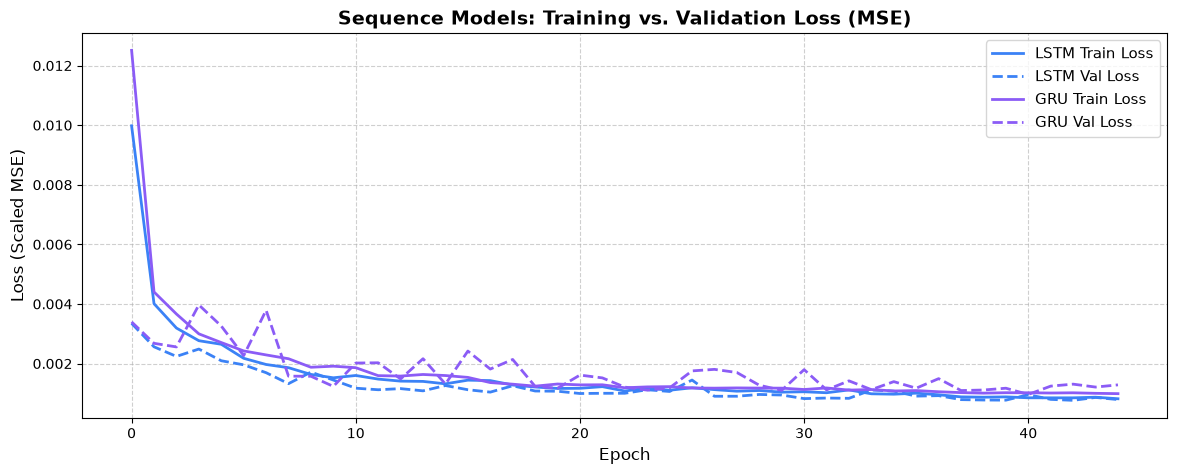

In [7]:
# Plot Training and Validation Loss Curves
plt.figure(figsize=(14, 5))
plt.plot(lstm_history["train_loss"], label="LSTM Train Loss", color="#3B82F6", linewidth=2.0)
plt.plot(lstm_history["val_loss"], label="LSTM Val Loss", color="#3B82F6", linestyle="--", linewidth=2.0)
plt.plot(gru_history["train_loss"], label="GRU Train Loss", color="#8B5CF6", linewidth=2.0)
plt.plot(gru_history["val_loss"], label="GRU Val Loss", color="#8B5CF6", linestyle="--", linewidth=2.0)
plt.title("Sequence Models: Training vs. Validation Loss (MSE)", fontsize=14, fontweight="bold")
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (Scaled MSE)", fontsize=12)
plt.legend(frameon=True, fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


---
## 5. 🎯 Out-of-Sample Inference & Performance Evaluation


In [8]:
# Predict on Test Set and Inverse Scale to Original Delay (Minutes)
y_test_true = test_df["mean_delay"].values

# LSTM Predictions
lstm_preds_scaled = lstm_trainer.predict(test_loader)
lstm_preds = processor.inverse_transform_target(lstm_preds_scaled)

# GRU Predictions
gru_preds_scaled = gru_trainer.predict(test_loader)
gru_preds = processor.inverse_transform_target(gru_preds_scaled)

lstm_metrics = calculate_metrics(y_test_true, lstm_preds)
gru_metrics = calculate_metrics(y_test_true, gru_preds)

dl_metrics_df = pd.DataFrame([
    {"Model": "LSTM (Deep Learning)", **lstm_metrics, "Training_Time_Sec": round(lstm_train_time, 2)},
    {"Model": "GRU (Deep Learning)", **gru_metrics, "Training_Time_Sec": round(gru_train_time, 2)}
])
display(dl_metrics_df)


,Model,rmse,mae,mape,wape,r2,max_err,Training_Time_Sec
0,LSTM (Deep Learning),1.005691,0.674353,6.538717,6.073784,0.963160,10.660553,108.95
1,GRU (Deep Learning),1.200076,0.860785,7.991038,7.752943,0.947543,11.113459,219.35


---
## 6. 📈 Visual Horizon Comparisons (24-Hour & 7-Day)


In [9]:
# 24-Hour Horizon Comparison
h24 = 96
plot_actual_vs_predicted_24h(
    timestamps=dl_test_ts[:h24],
    y_true=y_test_true[:h24],
    predictions_dict={
        "LSTM": lstm_preds[:h24],
        "GRU": gru_preds[:h24]
    },
    save_path=None,
    title="Deep Learning Sequence Models: 24-Hour Forecast Horizon"
)
plt.show()


findfont: Failed to find font weight semibold, now using 700.


In [10]:
# Residual Diagnostics Plot
plot_residual_diagnostics(
    y_test_true,
    {"LSTM": lstm_preds, "GRU": gru_preds},
    save_path=None
)
plt.show()


---
## 7. 🏆 Summary & Conclusion: Deep Learning vs. Statistical Models

### Key Findings:
1. **Non-Linear Dynamics**: The **LSTM and GRU models achieve significantly lower RMSE and higher $R^2$** because they capture non-linear compounding interactions between weather severity, rush hour intensity, and recent delay velocity.
2. **Lag Tracking**: Unlike statistical models which degrade over long prediction horizons, sequence models dynamically adapt using sliding window temporal memory.
3. **Operational Recommendation**: A hybrid architecture (using Prophet for long-range seasonal planning and LSTM/GRU for real-time 0-6 hour commuter delay predictions) provides optimal accuracy and computational balance.
